In [1]:
import anomaly_detection as ad
import pandas as pd
import os
import sys
import matplotlib.pyplot as plt

In [2]:
%%capture root_dir
!git rev-parse --show-toplevel
# Get the root directory for the github repo

In [3]:
root_dir = "".join(root_dir.stdout.split())

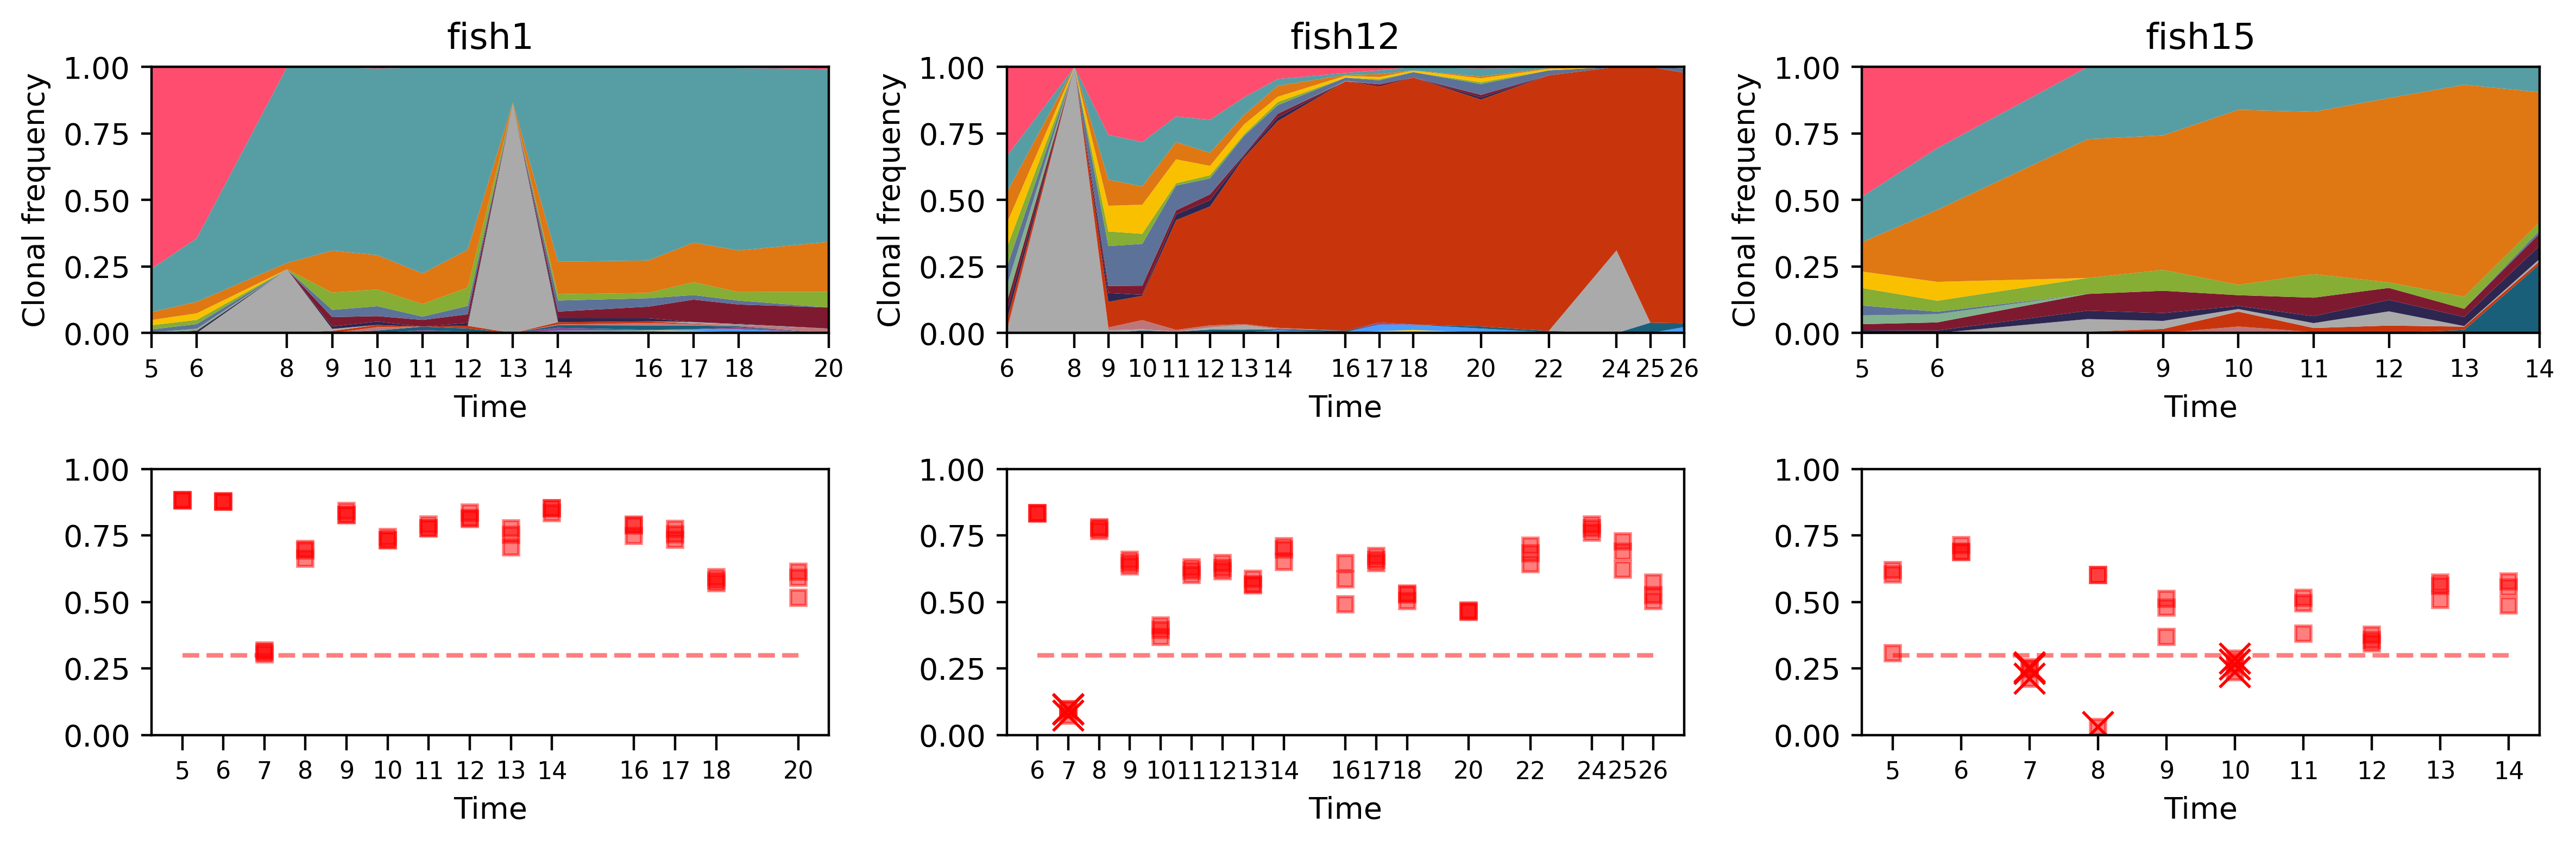

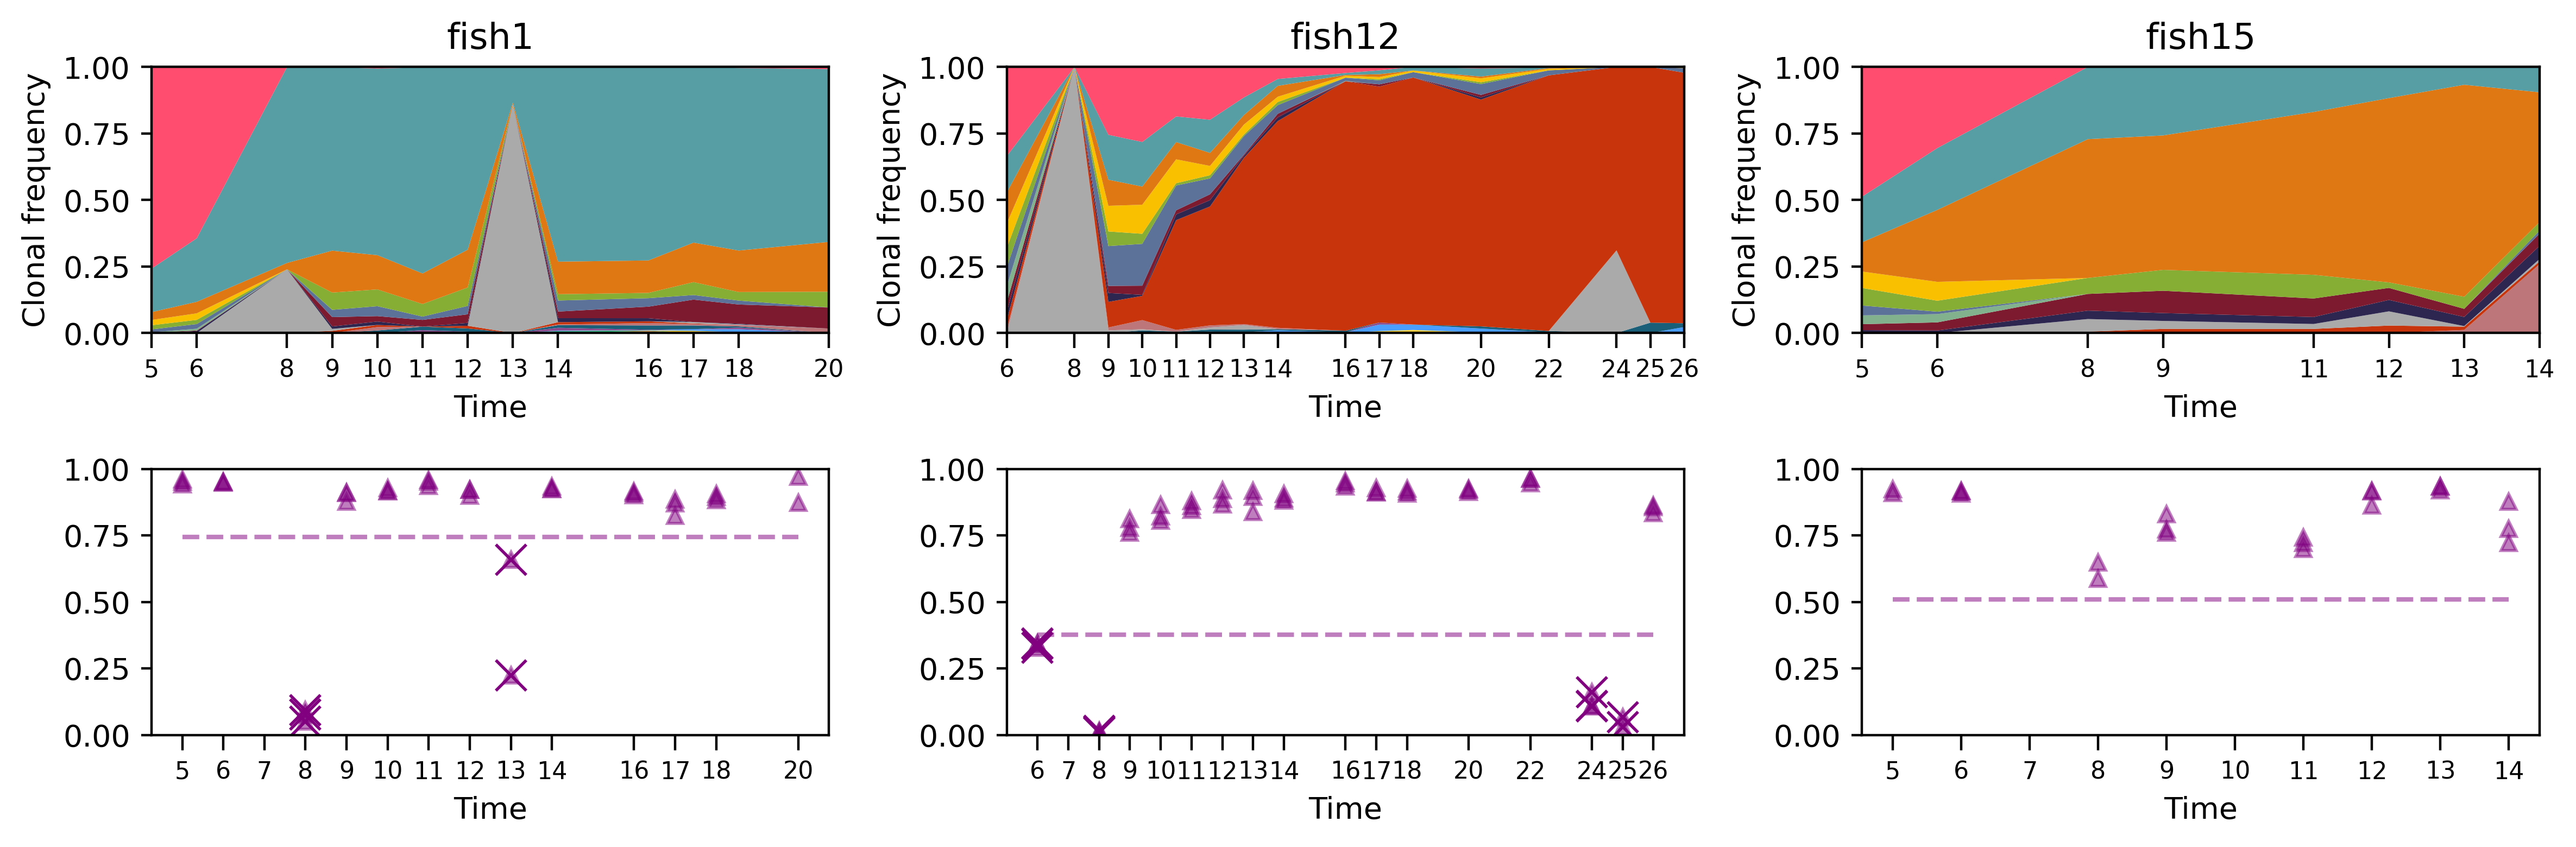

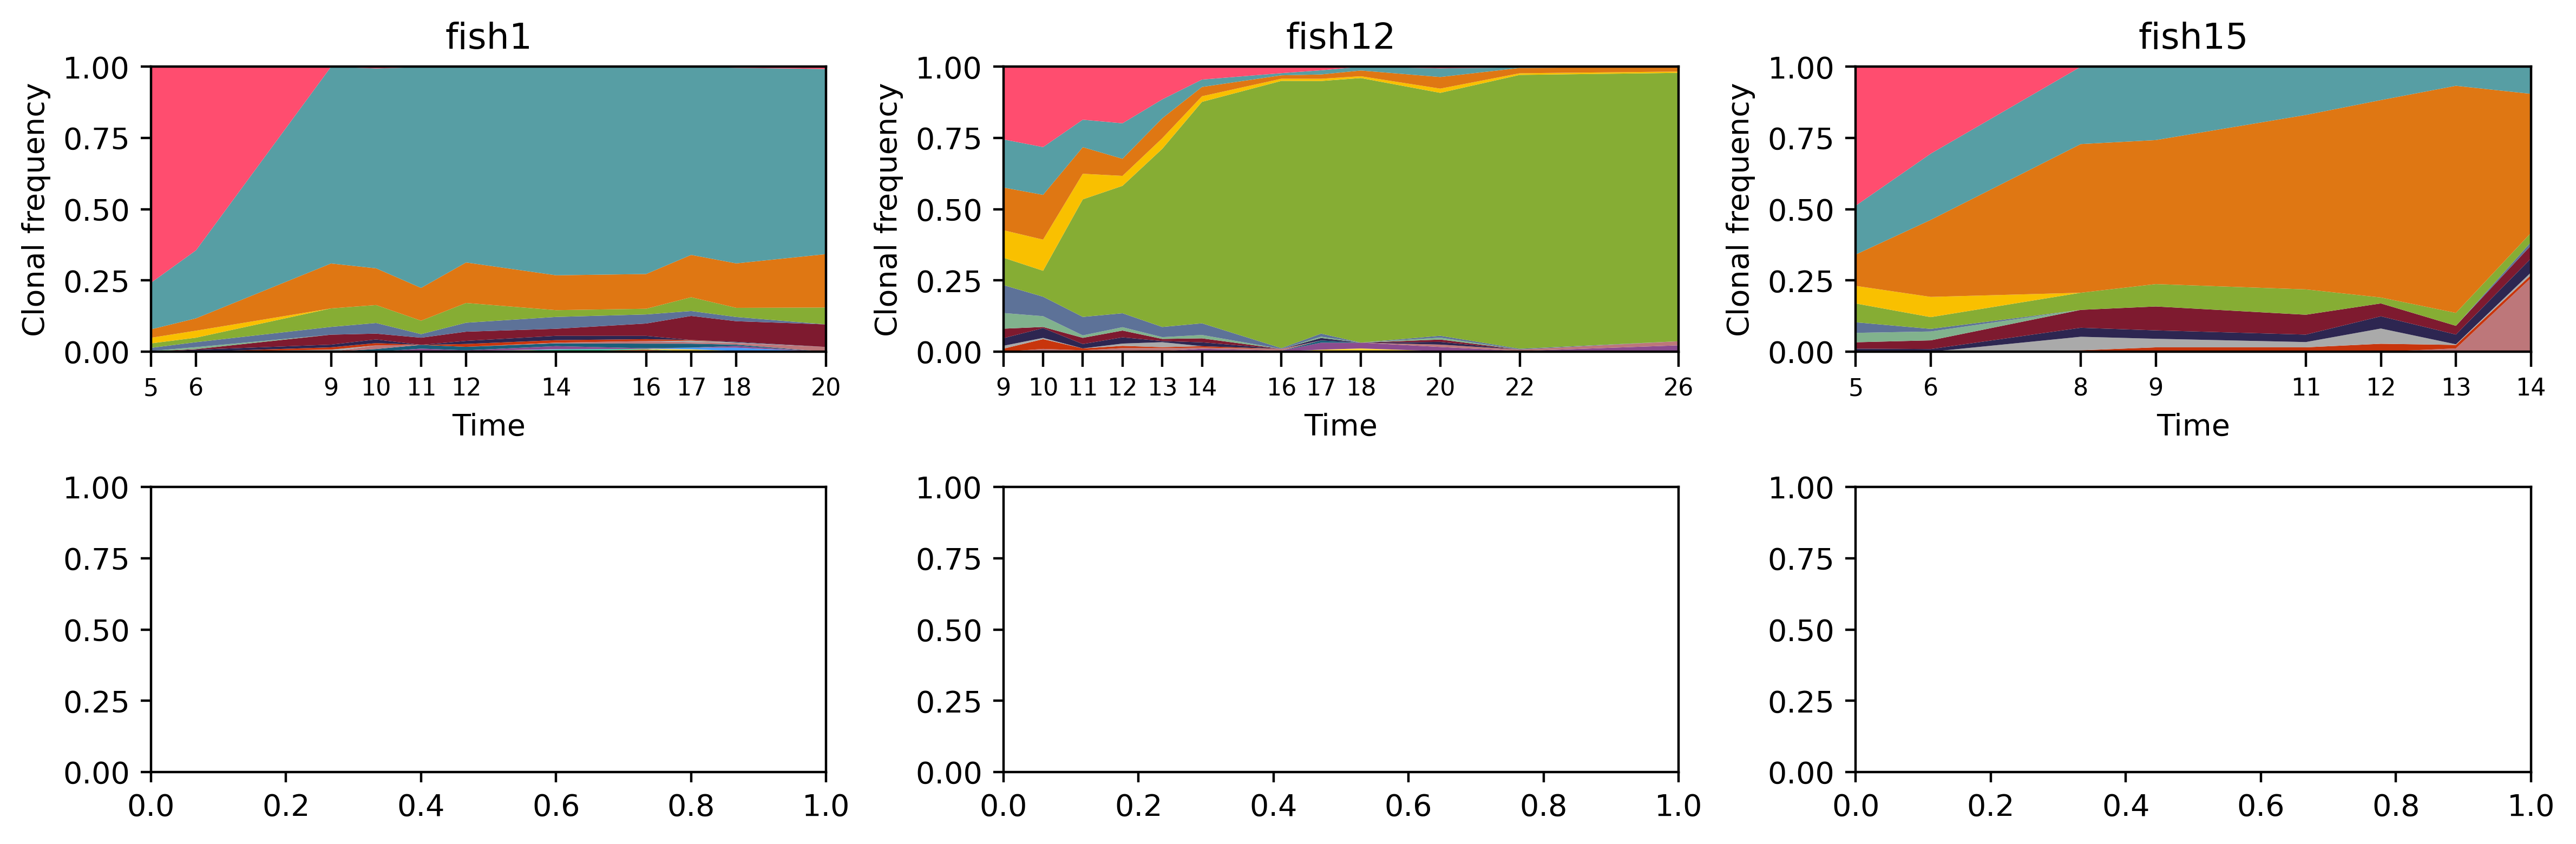

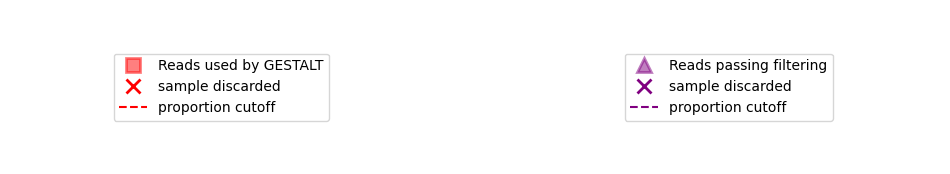

In [20]:
# Show mullers before and after anomaly detection

experiment1 = 'experiment-OG-nofilters'
data_file1 = f'{root_dir}/experiments/{experiment1}/final_data.csv'
data1 = pd.read_csv(data_file1)
metrics1 = ad.get_anomaly_metrics(experiment1, f'data/mp0.8_tq10', root_dir)

experiment2 = 'experiment-OG-usedfilter'
data_file2 = f'{root_dir}/experiments/{experiment2}/final_data.csv'
data2 = pd.read_csv(data_file2)
metrics2 = ad.get_anomaly_metrics(experiment2, f'data/mp0.8_tq10', root_dir)

experiment3 = 'experiment-OG'
data_file3 = f'{root_dir}/experiments/{experiment3}/final_data.csv'
data3 = pd.read_csv(data_file3)

# Get the array of fishes we want to plot (cherry-picked for filter demonstration)
fishes_to_plot = ['fish1', 'fish12', 'fish15']
fishes = fishes_to_plot

#fishes = data1['fish'].unique()

# Create custom legends
legend1_elements = [
    # Red square for "used entry prop"
    plt.Line2D([0], [0], marker='s', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='Reads used by GESTALT'),
    plt.Line2D([0], [0], marker='x', color='red', markerfacecolor='red', 
               markersize=10, markeredgewidth=2, linestyle='None', 
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='red', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='proportion cutoff'),

]
legend2_elements = [
    # Purple triangle for "kept entry prop"
    plt.Line2D([0], [0], marker='^', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None', alpha=0.5, 
               label='Reads passing filtering'),
    plt.Line2D([0], [0], marker='x', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='None',
               label='sample discarded'),
    plt.Line2D([0], [0], marker='None', color='purple', markerfacecolor='purple', 
               markersize=10, markeredgewidth=2, linestyle='--',
               label='proportion cutoff'),

]

# Section A
fig_width = len(fishes) * 4  # 4 inches per column
fig_height = 2 * 2

fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=400)

for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data1)
    ad.show_anomalies(fish, ax[1, i], data1, metrics1, show_filtered=False, map_samples=True)
    ax[0, i].tick_params(axis='x', labelsize=8, length=5)
    ax[1, i].tick_params(axis='x', labelsize=8, length=5)
plt.savefig(f'images/anomalies-no-filters.svg', format='svg')
plt.show()

# Section B
fig_width = len(fishes) * 4  # 4 inches per column
fig_height = 1 * 4

fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=400)

for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data2)
    ad.show_anomalies(fish, ax[1, i], data2, metrics2, show_used=False, map_samples=True)
    ax[0, i].tick_params(axis='x', labelsize=8, length=5)
    ax[1, i].tick_params(axis='x', labelsize=8, length=5)

plt.savefig(f'images/anomalies-first-filter.svg', format='svg')
plt.show()

# Section B
fig_width = len(fishes)  * 4  # 4 inches per column
fig_height = 1 * 4

fig, ax = plt.subplots(2, len(fishes), figsize=(fig_width, fig_height), dpi=400)

# Section C
for i, fish in enumerate(fishes):
    ad.plot_fish(fish, ax[0, i], data3)
    ax[0, i].tick_params(axis='x', labelsize=8, length=5)
plt.savefig(f'images/anomalies-all-filters.svg', format='svg')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 2))
ax[0].set_axis_off()
ax[1].set_axis_off()

legend = ax[0].legend(handles=legend1_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

legend = ax[1].legend(handles=legend2_elements, 
                   loc='center', 
                   ncol=1,  # Display in 1 columns
                   frameon=True)  # Keep frame

plt.savefig(f'images/anomalies-legend_seperate.svg', format='svg')
plt.show()